In [1]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )




In [2]:
df_DA_US=df[(df['job_title_short']=='Data Analyst')&(df['job_country']=='United States')].copy()


<Axes: >

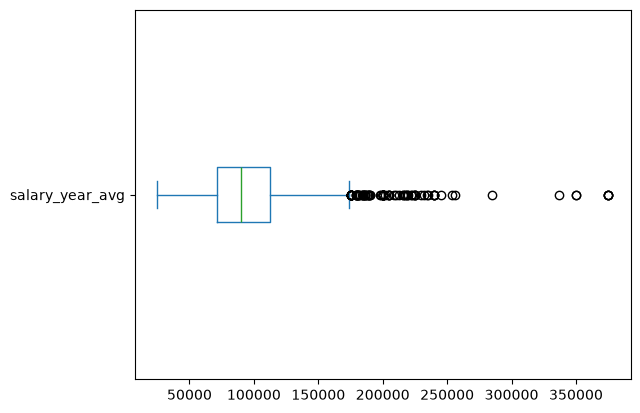

In [5]:
df_DA_US=df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US['salary_year_avg'].plot(kind='box',vert=False)

C:\Users\USER\AppData\Local\Temp\ipykernel_13968\1620243445.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list,tick_labels=job_titles,vert=False,flierprops=dict(marker='o', markersize=3, alpha=0.3))


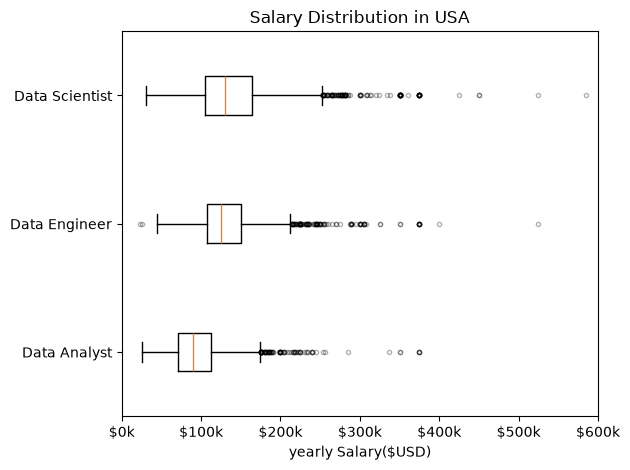

In [23]:
job_titles=['Data Analyst','Data Engineer','Data Scientist']
df_US=df[(df['job_title_short'].isin(job_titles))&(df['job_country']=='United States')].copy()
df_US=df_US.dropna(subset=['salary_year_avg'])

job_list=[df_US[df_US['job_title_short']==job_title]['salary_year_avg']for job_title in job_titles] 
plt.boxplot(job_list,tick_labels=job_titles,vert=False,flierprops=dict(marker='o', markersize=3, alpha=0.3))
ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,pos:f'${int(x/1000)}k'))
plt.title('Salary Distribution in USA')
plt.xlabel('yearly Salary($USD)')
plt.xlim(0,600000)
plt.tight_layout()

